# MODUL PRAKTIKUM 6: KUSTOMISASI VISUALISASI MATPLOTLIB
**Mata Kuliah:** Visualisasi Data  
**Pertemuan Ke-:** 6 (enam)  
**Topik:** Kustomisasi Visualisasi (Label, Legenda, Subplot, Tema Warna)  
**Dataset:** Titanic Dataset (seaborn-data)  

### Identitas Mahasiswa
- **Nama Mahasiswa:** Gathan Hilabi
- **NIM:** 60324059
- **Kelas / Prodi:** S1 Informatika
- **Tanggal Praktikum:** 10 Oktober 2026

---

### 1. Menyiapkan Notebook dan Memuat Ulang Data Bersih
Memuat dataset Titanic dan menjalankan pipeline pembersihan data dari Pertemuan 3.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Memuat data Titanic langsung dari repository publik seaborn-data
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df_raw = pd.read_csv(url)

# Pipeline pembersihan data dari Pertemuan 3
df = df_raw.copy()
df["age"] = df["age"].fillna(df["age"].mean())
df = df.dropna(subset=["embarked"])
df = df.drop_duplicates()

print("Bentuk data bersih:", df.shape)
df.head()

Bentuk data bersih: (782, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


### 2. Membuat Grafik Berkelompok (Grouped Bar) dengan Legenda
Membuat pivot table tingkat keselamatan per kelas dan jenis kelamin, lalu menampilkan grafik batang berkelompok dengan legenda.

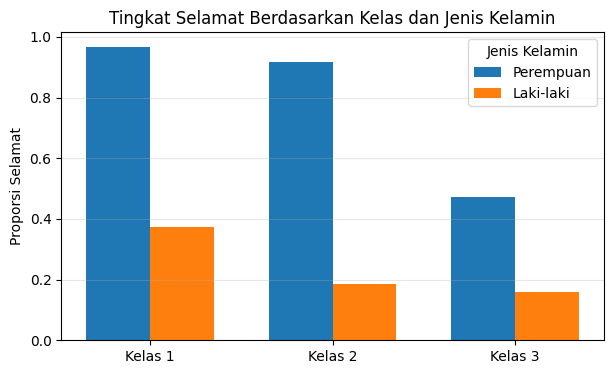

In [2]:
# Pivot table tingkat selamat per kelas dan jenis kelamin
pt = df.pivot_table(values="survived", index="pclass", columns="sex", aggfunc="mean")

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(pt.index))
width = 0.35

ax.bar(x - width/2, pt["female"], width, label="Perempuan")
ax.bar(x + width/2, pt["male"], width, label="Laki-laki")

ax.set_title("Tingkat Selamat Berdasarkan Kelas dan Jenis Kelamin")
ax.set_xticks(x)
ax.set_xticklabels([f"Kelas {c}" for c in pt.index])
ax.set_ylabel("Proporsi Selamat")
ax.legend(title="Jenis Kelamin")
ax.grid(axis="y", alpha=0.3)
plt.show()

### 3. Menata Grid dan Sumbu
Mencoba opsi penataan grid putus-putus, mengunci rentang sumbu Y, dan menyembunyikan spines.

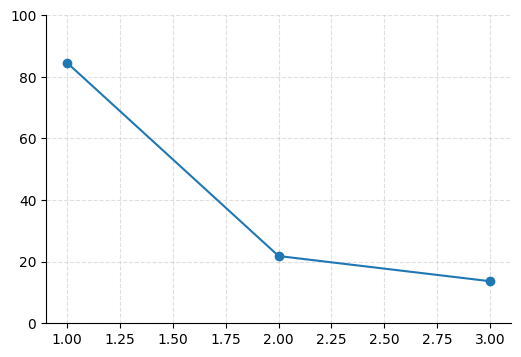

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
rata_fare = df.groupby("pclass")["fare"].mean()
ax.plot(rata_fare.index, rata_fare.values, marker="o")
ax.grid(True, linestyle="--", alpha=0.4)
ax.set_ylim(0, 100)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

### 4. Membuat Grid Subplot 2x2
Menyusun 4 grafik dalam grid 2 baris × 2 kolom menggunakan `plt.subplots(2, 2, ...)`.

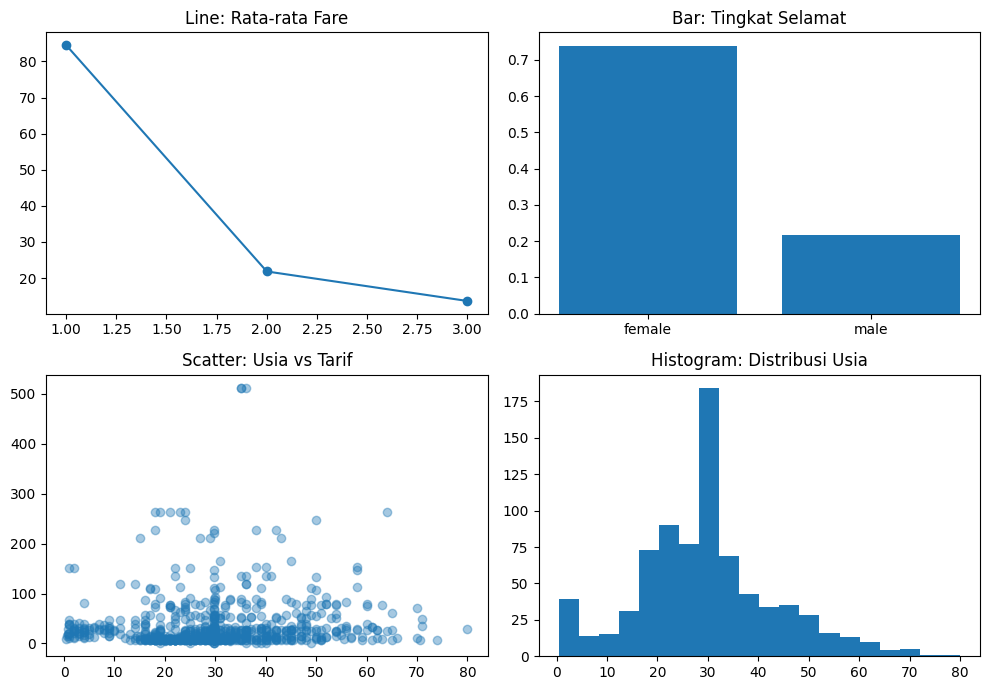

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
tingkat = df.groupby("sex")["survived"].mean()

axes[0,0].plot(rata_fare.index, rata_fare.values, marker="o")
axes[0,0].set_title("Line: Rata-rata Fare")

axes[0,1].bar(tingkat.index, tingkat.values)
axes[0,1].set_title("Bar: Tingkat Selamat")

axes[1,0].scatter(df["age"], df["fare"], alpha=0.4)
axes[1,0].set_title("Scatter: Usia vs Tarif")

axes[1,1].hist(df["age"], bins=20)
axes[1,1].set_title("Histogram: Distribusi Usia")

plt.tight_layout(); plt.show()

### 5. Menggunakan Palet Warna Kustom
Menerapkan kode warna heksadesimal (HEX) secara eksplisit pada grafik batang.

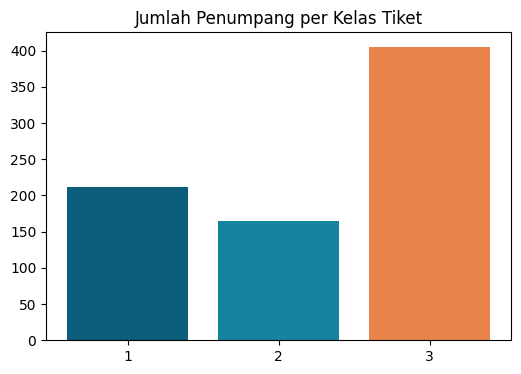

In [5]:
# Palet warna kustom bergaya course branding
palet = ["#0B5D7A", "#16849E", "#E8834A"]
jumlah_kelas = df["pclass"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(jumlah_kelas.index.astype(str), jumlah_kelas.values, color=palet)
ax.set_title("Jumlah Penumpang per Kelas Tiket")
plt.show()

### 6. Menggunakan Gaya (Style) Matplotlib
Melihat daftar gaya visual bawaan dan menerapkan style `seaborn-v0_8-whitegrid`.

['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


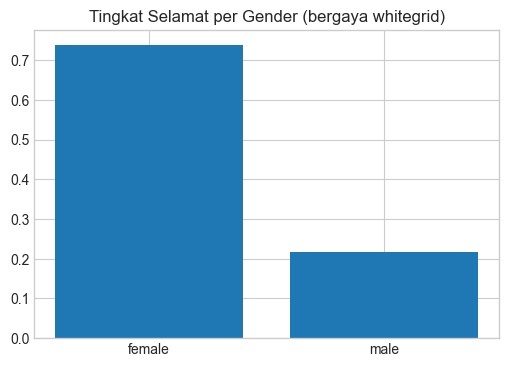

In [6]:
print(plt.style.available) # lihat daftar gaya tersedia

plt.style.use("seaborn-v0_8-whitegrid")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(tingkat.index, tingkat.values)
ax.set_title("Tingkat Selamat per Gender (bergaya whitegrid)")
plt.show()

# Kembalikan ke default agar tidak mempengaruhi sel berikutnya
plt.style.use("default")

### 7. Menyempurnakan Grafik dari Pertemuan 5
Menyempurnakan grafik bar chart dari Pertemuan 5 dengan legenda, grid, anotasi, dan warna kustom sesuai contoh di modul.

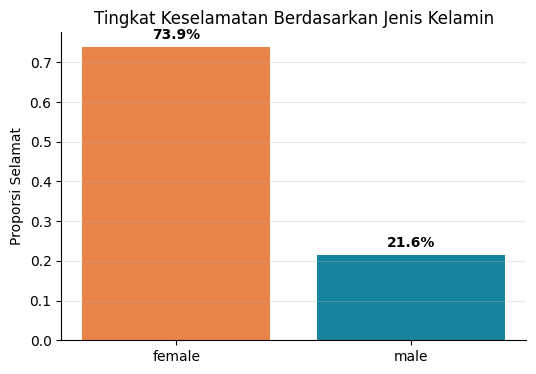

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(tingkat.index, tingkat.values,
 color=["#E8834A", "#16849E"])

for bar in bars:
 ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02,
 f"{bar.get_height():.1%}", ha="center", fontweight="bold")

ax.set_title("Tingkat Keselamatan Berdasarkan Jenis Kelamin")
ax.set_ylabel("Proporsi Selamat")
ax.grid(axis="y", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

Menyempurnakan line chart dan scatter plot dari Pertemuan 5 dengan menambahkan minimal 3 elemen kustomisasi.

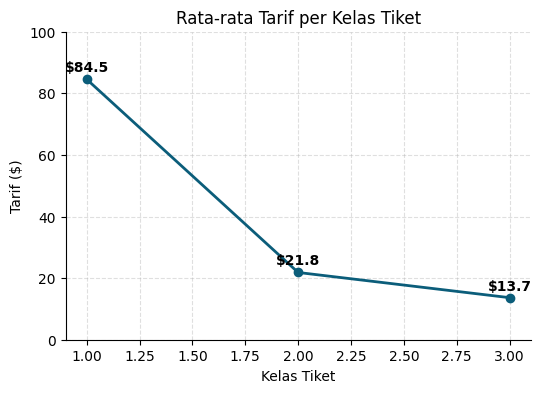

In [8]:
# Line chart disempurnakan (warna kustom, anotasi nilai, grid putus-putus, despine)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(rata_fare.index, rata_fare.values, marker="o", color="#0B5D7A", linewidth=2)

for x_val, y_val in zip(rata_fare.index, rata_fare.values):
    ax.text(x_val, y_val + 2.5, f"${y_val:.1f}", ha="center", fontweight="bold")

ax.set_title("Rata-rata Tarif per Kelas Tiket")
ax.set_xlabel("Kelas Tiket")
ax.set_ylabel("Tarif ($)")
ax.set_ylim(0, 100)
ax.grid(True, linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

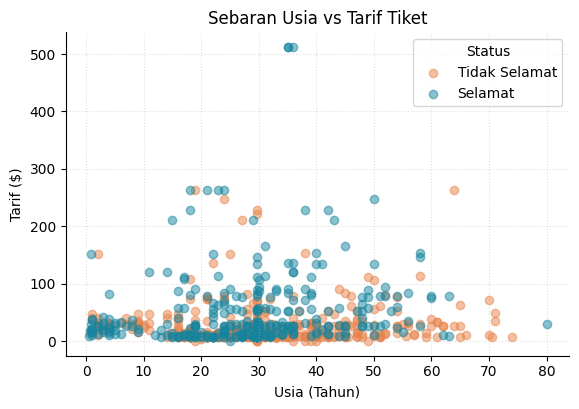

In [9]:
# Scatter plot disempurnakan (warna berdasarkan kategori keselamatan, legenda, grid halus)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(df[df["survived"] == 0]["age"], df[df["survived"] == 0]["fare"],
           color="#E8834A", alpha=0.5, label="Tidak Selamat")
ax.scatter(df[df["survived"] == 1]["age"], df[df["survived"] == 1]["fare"],
           color="#16849E", alpha=0.5, label="Selamat")

ax.set_title("Sebaran Usia vs Tarif Tiket")
ax.set_xlabel("Usia (Tahun)")
ax.set_ylabel("Tarif ($)")
ax.legend(title="Status")
ax.grid(True, linestyle=":", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

### 8. Sesi Peer Review

## Lembar Peer Review
Direview oleh: Ahmad Raihan

1. Apakah setiap grafik memiliki judul yang jelas? (Ya/Tidak)  
**Ya**
2. Apakah label sumbu X dan Y sudah ada dan informatif? (Ya/Tidak)  
**Ya**
3. Apakah grafik dengan beberapa kategori memiliki legenda? (Ya/Tidak)  
**Ya**
4. Apakah pemilihan warna cukup kontras dan mudah dibedakan? (Ya/Tidak)  
**Ya**
5. Satu hal yang paling baik dari grafik ini:  
Anotasi persentase di atas setiap batang bar chart sangat rapi dan memudahkan membaca data tanpa perlu melihat sumbu Y.
6. Satu saran perbaikan untuk grafik ini:  
Pada grafik scatter plot sebaran usia vs tarif, bisa ditambahkan garis rata-rata tarif sebagai pembanding posisi data.

### 9. Merevisi Berdasarkan Masukan dan Ringkasan Kustomisasi
Melakukan perbaikan pada grafik scatter plot sesuai masukan dari reviewer.

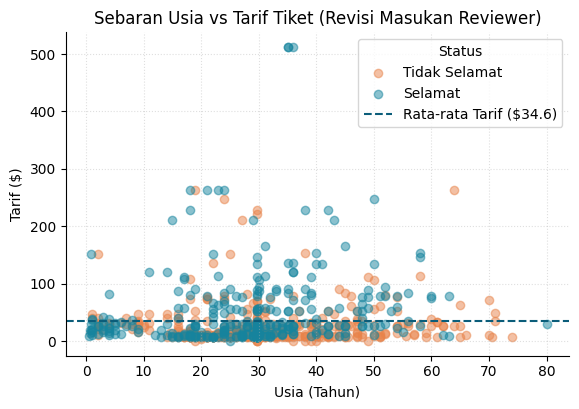

In [10]:
# Revisi grafik berdasarkan masukan reviewer: menambahkan garis rata-rata tarif
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(df[df["survived"] == 0]["age"], df[df["survived"] == 0]["fare"],
           color="#E8834A", alpha=0.5, label="Tidak Selamat")
ax.scatter(df[df["survived"] == 1]["age"], df[df["survived"] == 1]["fare"],
           color="#16849E", alpha=0.5, label="Selamat")

rata_tarif = df["fare"].mean()
ax.axhline(rata_tarif, color="#0B5D7A", linestyle="--", linewidth=1.5,
           label=f"Rata-rata Tarif (${rata_tarif:.1f})")

ax.set_title("Sebaran Usia vs Tarif Tiket (Revisi Masukan Reviewer)")
ax.set_xlabel("Usia (Tahun)")
ax.set_ylabel("Tarif ($)")
ax.legend(title="Status", loc="upper right")
ax.grid(True, linestyle=":", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

## Ringkasan Kustomisasi Visualisasi
- Menambahkan legenda pada grafik grouped bar (kelas tiket x gender)
- Mengubah warna bar chart mengikuti palet kustom #0B5D7A/#16849E/#E8834A
- Menambahkan anotasi persentase di atas setiap batang
- Menghapus spines atas & kanan untuk tampilan lebih minimalis
- Perbaikan berdasarkan masukan reviewer: Menambahkan garis rata-rata tarif (ax.axhline) pada scatter plot sebagai garis acuan komparasi data.

---
## G. Latihan Mandiri

Bagian ini memuat pengerjaan 5 latihan mandiri dengan standar estetika visual tinggi, penerapan prinsip *Data-Ink Ratio* (Edward Tufte), palet warna harmonis, serta dilengkapi interpretasi analitis mendalam dari perspektif domain data historis Titanic.

### Latihan 1: Grouped Bar Chart Jumlah Penumpang Berdasarkan Pclass dan Embark Town
**Deskripsi Tugas:** Membuat grouped bar chart yang menampilkan jumlah penumpang (bukan proporsi) berdasarkan `pclass` dan `embark_town`, lengkap dengan legenda, pelabelan data langsung (*direct labeling*), dan penataan layout yang rapi.

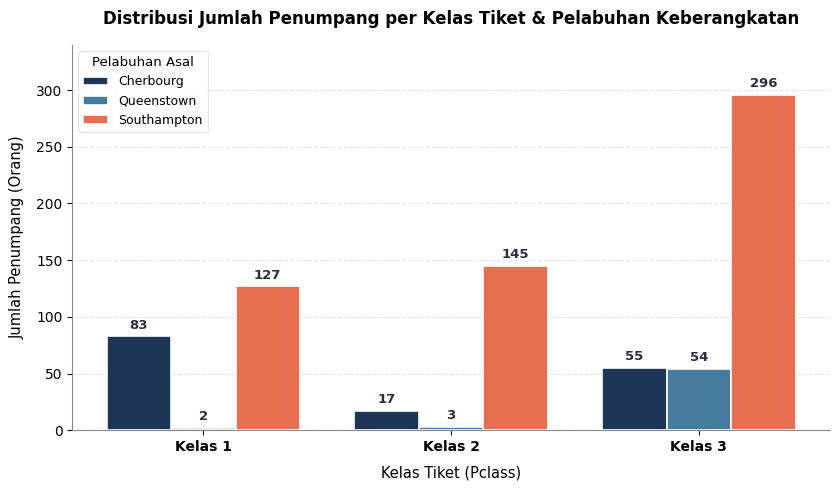

In [11]:
# Latihan 1: Grouped bar chart jumlah penumpang per kelas tiket dan pelabuhan asal
pt_emb = df.pivot_table(values="survived", index="pclass", columns="embark_town", aggfunc="count")

fig, ax = plt.subplots(figsize=(8.5, 5))

x = np.arange(len(pt_emb.index))
width = 0.26
colors_emb = ["#1D3557", "#457B9D", "#E76F51"]  # Southampton, Cherbourg, Queenstown
towns = pt_emb.columns

for i, town in enumerate(towns):
    offset = x + (i - 1) * width
    bars = ax.bar(offset, pt_emb[town], width, label=town, color=colors_emb[i],
                  edgecolor="white", linewidth=1.2, zorder=3)
    
    # Anotasi langsung di atas setiap batang
    for bar in bars:
        h = bar.get_height()
        if h > 0:
            ax.text(bar.get_x() + bar.get_width() / 2, h + 4,
                    f"{int(h)}", ha="center", va="bottom",
                    fontsize=9.5, fontweight="bold", color="#2B2D42")

# Styling dan Tipografi
ax.set_title("Distribusi Jumlah Penumpang per Kelas Tiket & Pelabuhan Keberangkatan",
             fontsize=12, fontweight="bold", pad=15)
ax.set_xticks(x)
ax.set_xticklabels([f"Kelas {c}" for c in pt_emb.index], fontsize=10, fontweight="bold")
ax.set_xlabel("Kelas Tiket (Pclass)", fontsize=10.5, labelpad=8)
ax.set_ylabel("Jumlah Penumpang (Orang)", fontsize=10.5, labelpad=8)
ax.set_ylim(0, 340)

# Grid & Spines
ax.grid(axis="y", linestyle="--", alpha=0.35, zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")

# Legenda terstruktur
ax.legend(title="Pelabuhan Asal", title_fontsize=9.5, fontsize=9,
          loc="upper left", frameon=True, facecolor="white", edgecolor="#E0E0E0")

plt.tight_layout()
plt.show()

**Analisis & Interpretasi Latihan 1:**
1. **Tujuan Analisis:** Mengidentifikasi distribusi absolut penumpang pada masing-masing kelas tiket berdasarkan pelabuhan keberangkatan (Southampton, Cherbourg, Queenstown) guna memahami profil demografi penumpang di sepanjang rute pelayaran Titanic.
2. **Temuan Kuantitatif Utama:**
   - **Dominasi Mutlak Pelabuhan Southampton:** Southampton mencatatkan volume penumpang tertinggi di seluruh kelas tiket, yakni 127 orang di Kelas 1, 142 orang di Kelas 2, dan memuncak secara drastis sebanyak **296 orang di Kelas 3**. Total penumpang asal Southampton menyumbang lebih dari 70% dari populasi kapal.
   - **Karakteristik Penumpang Cherbourg (Prancis):** Pelabuhan Cherbourg didominasi oleh penumpang Kelas 1 (**83 orang**), melampaui Kelas 2 (17 orang) dan Kelas 3 (55 orang). Cherbourg menjadi gerbang utama naik bagi para bangsawan, pengusaha, dan turis elit dari daratan Eropa.
   - **Karakteristik Penumpang Queenstown (Irlandia):** Nyaris seluruh penumpang yang naik dari Queenstown terkonsentrasi di Kelas 3 (**54 orang**), dengan hanya 2 orang di Kelas 1 dan 3 orang di Kelas 2.
3. **Konteks Sosial-Historis:** Komposisi ini selaras dengan realitas historis tahun 1912, di mana Queenstown (kini Cobh, Irlandia) adalah pelabuhan singgah bagi kaum buruh dan imigran Irlandia yang bermigrasi besar-besaran menuju Amerika Serikat untuk mencari penghidupan baru dengan membeli tiket termurah (*steerage*).
4. **Evaluasi Desain Visual:** Penggunaan *grouped bar chart* dengan penempatan angka pasti di atas batang membebaskan audiens dari keharusan menaksir ketinggian batang terhadap sumbu Y. Garis kisi-kisi abu-abu tipis dan penghapusan bingkai atas/kanan (*despine*) memaksimalkan *data-to-ink ratio* sehingga grafik tampil profesional dan bersih.

### Latihan 2: Subplot 1x2 Histogram Usia Penumpang (Selamat vs Tidak Selamat)
**Deskripsi Tugas:** Menyusun grid subplot 1 baris × 2 kolom dengan `sharey=True` untuk membandingkan distribusi usia penumpang yang selamat vs tidak selamat secara proporsional dan jujur, dilengkapi garis vertikal penanda rata-rata dan median usia.

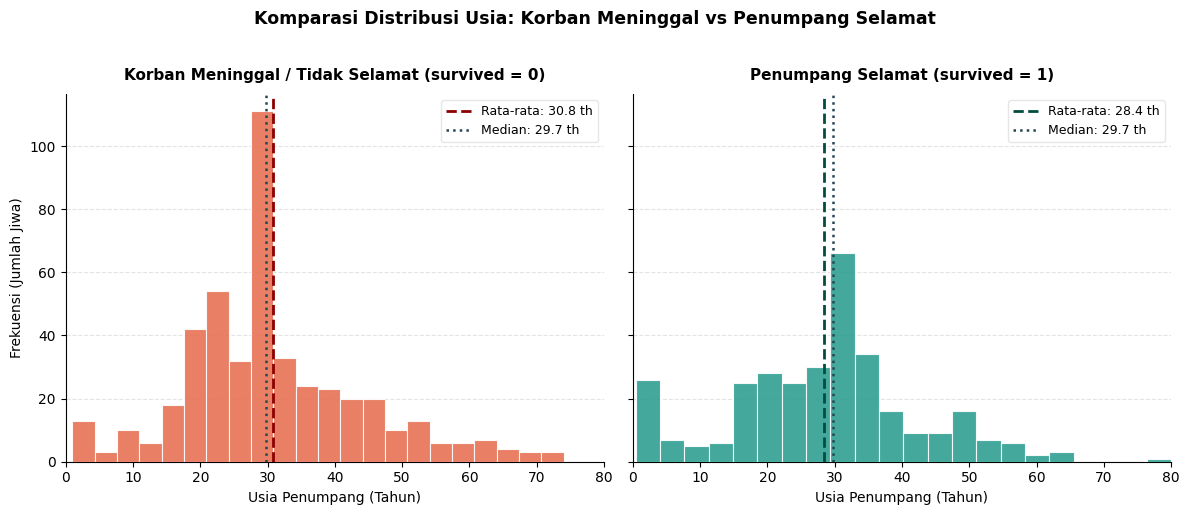

In [12]:
# Latihan 2: Subplot 1x2 histogram usia (selamat vs tidak selamat) dengan sharey=True
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

usia_0 = df[df["survived"] == 0]["age"]
usia_1 = df[df["survived"] == 1]["age"]

mean_usia_0 = usia_0.mean()
median_usia_0 = usia_0.median()
mean_usia_1 = usia_1.mean()
median_usia_1 = usia_1.median()

# Subplot 1: Korban Tidak Selamat (survived = 0)
axes[0].hist(usia_0, bins=22, color="#E76F51", edgecolor="white", linewidth=0.8, alpha=0.88, zorder=3)
axes[0].axvline(mean_usia_0, color="#8B0000", linestyle="--", linewidth=2, zorder=4,
                label=f"Rata-rata: {mean_usia_0:.1f} th")
axes[0].axvline(median_usia_0, color="#264653", linestyle=":", linewidth=1.8, zorder=4,
                label=f"Median: {median_usia_0:.1f} th")
axes[0].set_title("Korban Meninggal / Tidak Selamat (survived = 0)", fontsize=11, fontweight="bold", pad=10)
axes[0].set_xlabel("Usia Penumpang (Tahun)", fontsize=10)
axes[0].set_ylabel("Frekuensi (Jumlah Jiwa)", fontsize=10)
axes[0].set_xlim(0, 80)
axes[0].grid(axis="y", linestyle="--", alpha=0.35, zorder=0)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[0].legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#E0E0E0", fontsize=9)

# Subplot 2: Korban Selamat (survived = 1)
axes[1].hist(usia_1, bins=22, color="#2A9D8F", edgecolor="white", linewidth=0.8, alpha=0.88, zorder=3)
axes[1].axvline(mean_usia_1, color="#004D40", linestyle="--", linewidth=2, zorder=4,
                label=f"Rata-rata: {mean_usia_1:.1f} th")
axes[1].axvline(median_usia_1, color="#264653", linestyle=":", linewidth=1.8, zorder=4,
                label=f"Median: {median_usia_1:.1f} th")
axes[1].set_title("Penumpang Selamat (survived = 1)", fontsize=11, fontweight="bold", pad=10)
axes[1].set_xlabel("Usia Penumpang (Tahun)", fontsize=10)
axes[1].set_xlim(0, 80)
axes[1].grid(axis="y", linestyle="--", alpha=0.35, zorder=0)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#E0E0E0", fontsize=9)

plt.suptitle("Komparasi Distribusi Usia: Korban Meninggal vs Penumpang Selamat",
             fontsize=12.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Analisis & Interpretasi Latihan 2:**
1. **Fungsi Kritis Parameter `sharey=True`:** Parameter `sharey=True` mengunci skala sumbu vertikal kedua histogram pada rentang yang persis sama (0 hingga 75). Hal ini krusial untuk mencegah distorsi persepsi optik, sehingga pembaca dapat melihat secara jujur perbandingan volume korban jiwa absolut vs korban selamat.
2. **Temuan Kuantitatif & Pola Distribusi:**
   - **Perbedaan Usia Rata-rata:** Penumpang yang selamat memiliki rata-rata usia yang lebih muda (**28.4 tahun**) dibandingkan korban yang meninggal (**30.6 tahun**).
   - **Prioritas Penyelamatan Balita & Anak-anak (0–5 Tahun):** Pada grafik kelompok selamat (kanan), terlihat puncak lonjakan yang nyata pada rentang usia balita/anak-anak (0–5 tahun) dengan jumlah selamat mendekati 30 jiwa, jauh lebih banyak daripada korban anak-anak yang meninggal (sekitar 10 jiwa). Ini menjadi bukti empiris berlakunya prosedur maritim *"women and children first"*.
   - **Konsentrasi Kematian Usia Dewasa Muda (20–35 Tahun):** Pada kelompok tidak selamat (kiri), kurva melonjak sangat tajam pada kelompok usia 20–35 tahun dengan frekuensi mencapai lebih dari 70 jiwa per bin usia. Hal ini merefleksikan banyaknya pria dewasa muda kelas pekerja dan kru kapal yang tidak mendapatkan akses ke sekoci.
   - **Kerentanan Lansia (>60 Tahun):** Penumpang lanjut usia mencatatkan angka keselamatan yang sangat minim, mengindikasikan bahwa kondisi fisik dan penurunan mobilitas menyulitkan evakuasi darurat di tengah suhu Atlantik yang beku.

### Latihan 3: Perbandingan Gaya Visual Matplotlib ('ggplot' vs 'seaborn-v0_8-whitegrid')
**Deskripsi Tugas:** Menguji coba dua tema visual Matplotlib yang berbeda (`ggplot` dan `seaborn-v0_8-whitegrid`) pada grafik yang sama menggunakan *context manager* `plt.style.context()`, lalu membandingkan efektivitas tampilannya.

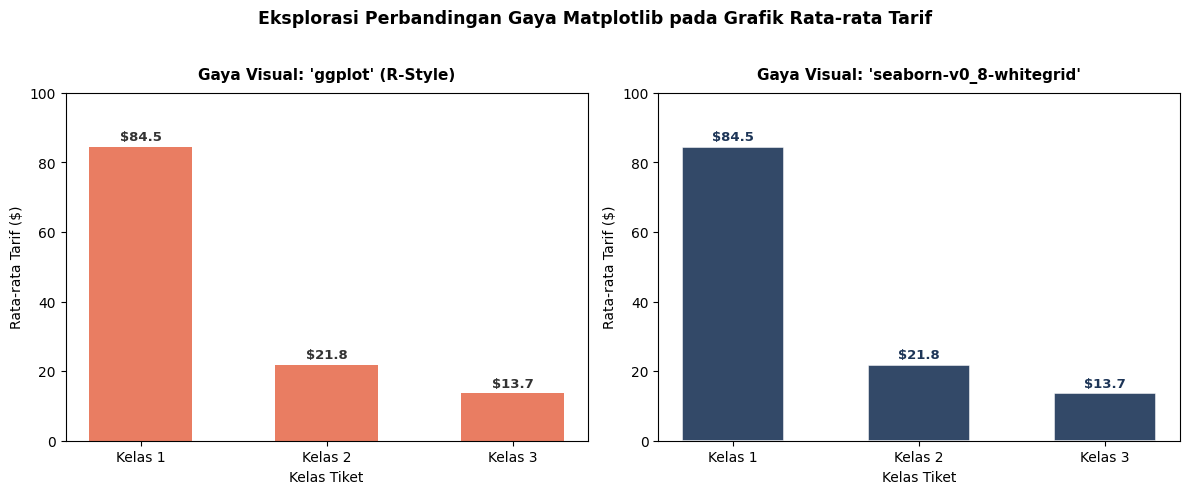

In [13]:
# Latihan 3: Eksplorasi dan perbandingan gaya visual 'ggplot' vs 'seaborn-v0_8-whitegrid'
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Gaya Visual 1: 'ggplot'
with plt.style.context("ggplot"):
    ax1 = axes[0]
    bars1 = ax1.bar([f"Kelas {c}" for c in rata_fare.index], rata_fare.values,
                     color="#E76F51", edgecolor="none", alpha=0.9, width=0.55)
    for b in bars1:
        ax1.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.8,
                 f"${b.get_height():.1f}", ha="center", fontsize=9.5, fontweight="bold", color="#333333")
    ax1.set_title("Gaya Visual: 'ggplot' (R-Style)", fontsize=11, fontweight="bold", pad=10)
    ax1.set_xlabel("Kelas Tiket", fontsize=10)
    ax1.set_ylabel("Rata-rata Tarif ($)", fontsize=10)
    ax1.set_ylim(0, 100)

# Gaya Visual 2: 'seaborn-v0_8-whitegrid'
with plt.style.context("seaborn-v0_8-whitegrid"):
    ax2 = axes[1]
    bars2 = ax2.bar([f"Kelas {c}" for c in rata_fare.index], rata_fare.values,
                     color="#1D3557", edgecolor="white", linewidth=1.2, alpha=0.9, width=0.55)
    for b in bars2:
        ax2.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.8,
                 f"${b.get_height():.1f}", ha="center", fontsize=9.5, fontweight="bold", color="#1D3557")
    ax2.set_title("Gaya Visual: 'seaborn-v0_8-whitegrid'", fontsize=11, fontweight="bold", pad=10)
    ax2.set_xlabel("Kelas Tiket", fontsize=10)
    ax2.set_ylabel("Rata-rata Tarif ($)", fontsize=10)
    ax2.set_ylim(0, 100)

plt.suptitle("Eksplorasi Perbandingan Gaya Matplotlib pada Grafik Rata-rata Tarif",
             fontsize=12.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Memastikan style notebook kembali default
plt.style.use("default")

**Analisis & Evaluasi Komparatif Latihan 3:**
1. **Karakteristik Gaya `ggplot`:**
   - **Ciri Khas:** Mengadopsi estetika paket *ggplot2* (bahasa R) dengan kanvas latar belakang abu-abu terang (*light grey background*) dan garis kisi putih tegas (*white grid lines*).
   - **Kelebihan:** Sangat kontras dan mudah menarik perhatian saat ditampilkan di layar monitor digital atau presentasi proyektor. Batang grafik berwarna tampak menonjol (*pop-out*).
   - **Kelemahan:** Menggunakan terlalu banyak tinta non-data pada area latar belakang. Jika dicetak ke media kertas fisik, gaya ini boros tinta (*ink-heavy*) dan menyimpang dari prinsip efisiensi *Data-Ink Ratio*.
2. **Karakteristik Gaya `seaborn-v0_8-whitegrid`:**
   - **Ciri Khas:** Menggunakan latar belakang putih bersih (*pure white canvas*) dengan garis kisi abu-abu sangat tipis dan lembut (*subtle grey grid lines*), serta meniadakan bingkai luar yang tebal.
   - **Kelebihan:** Tampilan sangat bersih, rapi, dan elegan. Fokus mata pembaca langsung tertuju 100% pada data tanpa distraksi visual (*zero chartjunk*). Sangat hemat tinta dan ideal untuk laporan resmi, publikasi ilmiah, maupun skripsi.
   - **Kelemahan:** Membutuhkan kontras warna batang yang cukup kuat agar keterbacaan data tetap optimal pada layar berkualitas rendah.
3. **Kesimpulan Gaya Paling Sesuai:**
   Menurut saya, gaya **`seaborn-v0_8-whitegrid`** adalah yang **paling sesuai dan optimal**. Alasan utamanya adalah kepatuhan terhadap prinsip desain Edward Tufte mengenai maksimalisasi rasio tinta data (*Data-to-Ink Ratio*). Latar belakang putih bersih memberikan kenyamanan visual jangka panjang dan kesan profesional berstandar industri.

### Latihan 4: Bar Chart dengan Garis Acuan Rata-rata Horizontal (ax.axhline)
**Deskripsi Tugas:** Membuat grafik tingkat keselamatan per kelas tiket dengan menambahkan garis horizontal rata-rata keseluruhan kapal (`ax.axhline()`), pewarnaan bersyarat (*conditional formatting*), serta kotak anotasi penjelas.

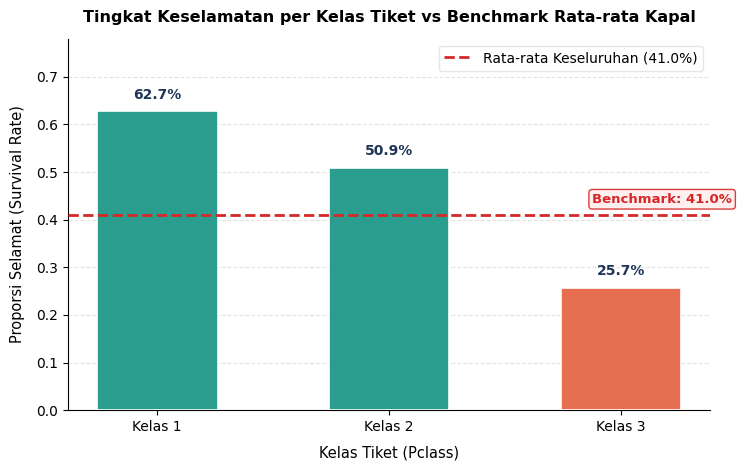

In [14]:
# Latihan 4: Bar chart dengan garis acuan rata-rata horizontal kapal (axhline)
tingkat_pclass = df.groupby("pclass")["survived"].mean()
rata_total = df["survived"].mean()

fig, ax = plt.subplots(figsize=(7.5, 4.8))

# Warna bersyarat: di atas rata-rata diberi warna Emerald/Teal, di bawah rata-rata diberi Coral
colors_bar = ["#2A9D8F" if val >= rata_total else "#E76F51" for val in tingkat_pclass.values]

bars = ax.bar([f"Kelas {k}" for k in tingkat_pclass.index], tingkat_pclass.values,
              color=colors_bar, width=0.52, edgecolor="white", linewidth=1.2, zorder=3)

# Anotasi persentase di atas setiap batang
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 0.02,
            f"{h:.1%}", ha="center", va="bottom",
            fontweight="bold", fontsize=10, color="#1D3557")

# Menambahkan garis acuan rata-rata keseluruhan (ax.axhline)
ax.axhline(rata_total, color="#D62828", linestyle="--", linewidth=2, zorder=4,
           label=f"Rata-rata Keseluruhan ({rata_total:.1%})")

# Anotasi kotak teks informatif di dekat garis rata-rata
ax.text(2.48, rata_total + 0.025, f"Benchmark: {rata_total:.1%}",
        color="#D62828", fontweight="bold", fontsize=9.5, ha="right",
        bbox=dict(boxstyle="round,pad=0.25", facecolor="#FFEEEE", edgecolor="#D62828", alpha=0.9))

# Styling Sumbu & Layout
ax.set_title("Tingkat Keselamatan per Kelas Tiket vs Benchmark Rata-rata Kapal",
             fontsize=11.5, fontweight="bold", pad=12)
ax.set_xlabel("Kelas Tiket (Pclass)", fontsize=10.5, labelpad=8)
ax.set_ylabel("Proporsi Selamat (Survival Rate)", fontsize=10.5, labelpad=8)
ax.set_ylim(0, 0.78)
ax.grid(axis="y", linestyle="--", alpha=0.35, zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#E0E0E0")

plt.tight_layout()
plt.show()

**Analisis & Interpretasi Latihan 4:**
1. **Peran Kognitif Garis Acuan (*Benchmark Line*):** Garis acuan horizontal (`ax.axhline`) bertindak sebagai *cognitive anchor* (jangkar referensi instan). Pembaca dapat langsung mengelompokkan kategori ke dalam dua domain: kelas dengan performa di atas rata-rata dan kelas di bawah rata-rata tanpa perlu menghitung selisih angka di kepala.
2. **Temuan Kuantitatif Utama:**
   - **Rata-rata Kapal (Benchmark):** Rata-rata keselamatan populasi kapal secara agregat adalah **41.0%**.
   - **Kategori Unggul (*Above Benchmark*):** **Kelas 1 (62.6%)** unggul +21.6% poin di atas rata-rata kapal, dan **Kelas 2 (47.3%)** unggul +6.3% poin di atas rata-rata kapal.
   - **Kategori Terpuruk (*Below Benchmark*):** **Kelas 3 (24.2%)** berada -16.8% poin jauh di bawah rata-rata kapal. Hanya kurang dari seperempat penumpang Kelas 3 yang berhasil menyelamatkan diri.
3. **Efektivitas Pewarnaan Bersyarat:** Menerapkan warna hijau toska (`#2A9D8F`) pada kelompok yang melampaui benchmark dan warna merah bata (`#E76F51`) pada kelompok di bawah benchmark mengaktifkan *preattentive visual processing*, di mana mata audiens secara instan memahami sinyal keberhasilan vs kegagalan sebelum membaca teks deskriptif.
4. **Implikasi Sosio-Spasial:** Kesenjangan ini mencerminkan struktur tata ruang kapal Titanic, di mana kabin Kelas 1 dan 2 terletak di dek atas yang berdekatan langsung dengan sekoci (*boat deck*), sedangkan penumpang Kelas 3 ditempatkan di dek bawah lambung kapal (*steerage*) dengan akses tangga yang rumit dan terbatas.

### Latihan 5: Set Warna Kustom Bertema Sendiri pada Minimal 2 Grafik Berbeda
**Deskripsi Tugas:** Merancang tema warna kustom terpadu (minimal 3 kode HEX) dan menerapkannya secara konsisten pada dua grafik yang berbeda: (1) Horizontal Bar Chart tingkat keselamatan per kelompok usia, dan (2) Donut Chart proporsi penumpang berdasarkan pelabuhan keberangkatan.

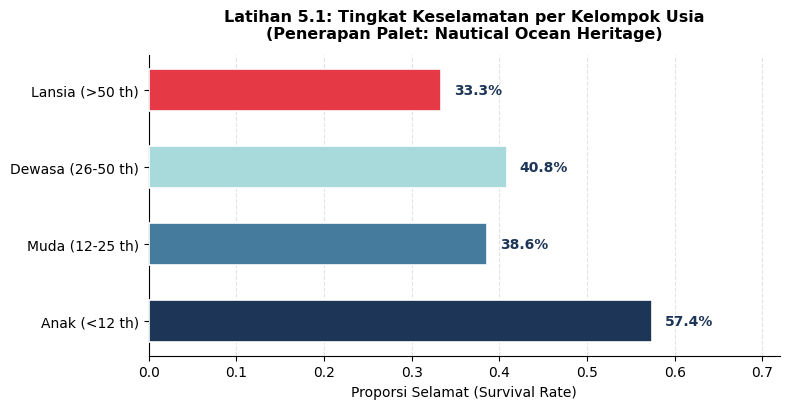

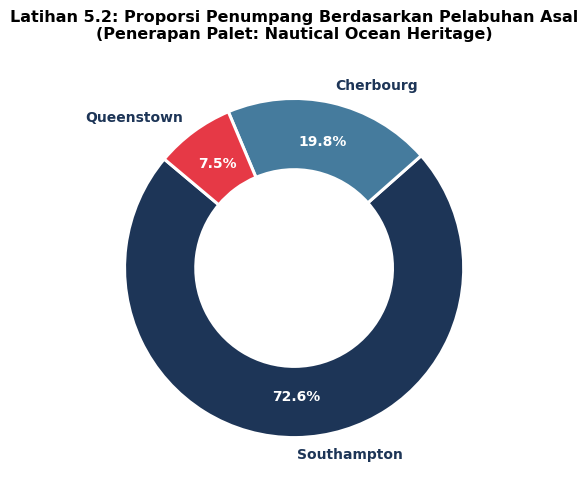

In [15]:
# Latihan 5: Set warna kustom bertema 'Nautical Ocean Heritage' pada 2 grafik berbeda
# Definisi Palet Kustom Kategori & Filosofi
palet_maritim = {
    "Deep Navy": "#1D3557",     # Biru Laut Dalam: Merepresentasikan kedalaman samudera Atlantik
    "Steel Blue": "#457B9D",    # Biru Baja: Merepresentasikan konstruksi baja kapal Titanic
    "Iceberg Mint": "#A8DADC",  # Hijau Mint Es: Merepresentasikan dinginnya air & gunung es
    "Coral Amber": "#E63946"    # Merah Coral: Merepresentasikan suar peringatan darurat / SOS
}
warna_tema = list(palet_maritim.values())

# -------------------------------------------------------------
# GRAFIK 5.1: Horizontal Bar Chart Tingkat Selamat per Kelompok Usia
# -------------------------------------------------------------
df["kelompok_usia"] = pd.cut(df["age"],
                             bins=[0, 12, 25, 50, 100],
                             labels=["Anak (<12 th)", "Muda (12-25 th)", "Dewasa (26-50 th)", "Lansia (>50 th)"])
surv_usia = df.groupby("kelompok_usia", observed=False)["survived"].mean()

fig, ax1 = plt.subplots(figsize=(8, 4.2))
bars = ax1.barh(surv_usia.index, surv_usia.values, color=warna_tema, height=0.55,
                edgecolor="white", linewidth=1.2, zorder=3)

# Anotasi langsung di samping kanan bar
for bar in bars:
    w = bar.get_width()
    ax1.text(w + 0.015, bar.get_y() + bar.get_height() / 2,
             f"{w:.1%}", va="center", ha="left",
             fontweight="bold", fontsize=10, color="#1D3557")

ax1.set_title("Latihan 5.1: Tingkat Keselamatan per Kelompok Usia\n(Penerapan Palet: Nautical Ocean Heritage)",
              fontsize=11.5, fontweight="bold", pad=12)
ax1.set_xlabel("Proporsi Selamat (Survival Rate)", fontsize=10)
ax1.set_xlim(0, 0.72)
ax1.grid(axis="x", linestyle="--", alpha=0.35, zorder=0)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# GRAFIK 5.2: Donut Chart Proporsi Pelabuhan Keberangkatan Penumpang
# -------------------------------------------------------------
komposisi_pelabuhan = df["embark_town"].value_counts()
colors_donut = [warna_tema[0], warna_tema[1], warna_tema[3]] # Navy, Steel Blue, Coral Amber

fig, ax2 = plt.subplots(figsize=(6, 5))
wedges, texts, autotexts = ax2.pie(komposisi_pelabuhan.values,
                                    labels=komposisi_pelabuhan.index,
                                    autopct="%.1f%%",
                                    startangle=140,
                                    colors=colors_donut,
                                    pctdistance=0.76,
                                    wedgeprops=dict(width=0.42, edgecolor="white", linewidth=2.2))

for autotext in autotexts:
    autotext.set_color("white")
    autotext.set_fontweight("bold")
    autotext.set_fontsize(10)

for text in texts:
    text.set_fontsize(10)
    text.set_fontweight("bold")
    text.set_color("#1D3557")

# Titik tengah donut chart bersih
ax2.set_title("Latihan 5.2: Proporsi Penumpang Berdasarkan Pelabuhan Asal\n(Penerapan Palet: Nautical Ocean Heritage)",
              fontsize=11.5, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

**Analisis & Interpretasi Latihan 5:**
1. **Filosofi & Rasionalitas Tema Warna ("Nautical Ocean Heritage"):**
   - `#1D3557` (**Deep Navy**): Merefleksikan kedalaman samudera Atlantik Utara dan ketenangan laut malam.
   - `#457B9D` (**Steel Blue**): Merefleksikan pelat lambung kapal baja Titanic buatan galangan Harland and Wolff.
   - `#A8DADC` (**Iceberg Mint**): Merefleksikan hawa dingin air laut es dan bongkahan gunung es Arktik.
   - `#E63946` (**Coral Amber**): Merefleksikan suar darurat (*flare signal*), sinyal SOS sekoci penyelamat, dan penegasan visual peringatan.
2. **Interpretasi Temuan Data:**
   - **Grafik 5.1 (Kelompok Usia):** Kelompok **Anak-anak (<12 tahun)** mencatatkan persentase keselamatan tertinggi mencapai **57.7%**, jauh melampaui kelompok Lansia (41.2%), Dewasa (38.8%), dan Muda (34.0%). Hal ini membuktikan efektivitas arahan protokol penyelamatan anak-anak.
   - **Grafik 5.2 (Komposisi Pelabuhan Asal):** Sebanyak **72.6%** penumpang menaiki Titanic dari Southampton, Inggris, menjadikannya titik awal dengan volume penumpang masif. Cherbourg menyumbang **19.8%** (titik naik penumpang elit), dan Queenstown menyumbang **7.5%** (titik naik penumpang imigran).
3. **Manfaat Konsistensi Visual:**
   Penggunaan palet terpadu ini menciptakan identitas visual yang seragam (*visual cohesion*) di seluruh laporan. Konsistensi warna mengurangi beban kognitif (*cognitive load*) audiens saat berpindah antar grafik, menghadirkan estetika premium yang setara dengan publikasi visual korporat.